<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-03/homework3.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Tarea 3: Análisis de escasez en imágenes

**Muestreo comprimido — INF-449, Universidad Técnica Federico Santa María**

En este notebook se resuelven los dos ejercicios de la guía. Se estudia cómo cambia la representación de una imagen cuando se utilizan una base Wavelet-2D y una base DCT-2D. Después se eliminan coeficientes pequeños, se reconstruyen las imágenes y se cuantifica la pérdida mediante PSNR.

La idea central, de acuerdo con la clase, es representar una señal como

$$x = \Psi\theta,$$

donde $x \in \mathbb{R}^{n}$ es la imagen vectorizada, $\Psi \in \mathbb{R}^{n \times n}$ es una base de representación y $\theta \in \mathbb{R}^{n}$ contiene los coeficientes. Si la base es ortonormal, $\Psi^{T}\Psi = I$ y los coeficientes se obtienen mediante $\theta = \Psi^{T}x$. Una representación es más dispersa cuando la energía de $x$ se concentra en pocos coeficientes significativos.

## 1. Enunciado y estrategia de resolución

Para cada imagen se hará lo siguiente:

1. Leer y normalizar la imagen a `[0, 1]`.
2. Calcular la transformación Wavelet-2D y DCT-2D.
3. Vectorizar los coeficientes y ordenarlos de mayor a menor magnitud.
4. Comparar la concentración de energía de ambas representaciones.
5. Repetir el segundo ejercicio para `coins`, `cameraman` y `astronaut`.
6. Conservar solamente el 5%, 10%, 20% y 50% de los coeficientes de mayor magnitud.
7. Aplicar las transformaciones inversas y calcular MSE y PSNR.

Se utiliza la wavelet de Haar porque es una wavelet 2-D ortonormal, sencilla de implementar y suficiente para estudiar el concepto de escasez. En Matlab, `wavedec2` puede producir otra familia wavelet; por eso los valores numéricos pueden cambiar, pero el procedimiento y la interpretación son los mismos. En este notebook $n = 256 \times 256 = 65\,536$, por lo que cada base genera exactamente esa cantidad de coeficientes.

## 2. Preparación del entorno

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dctn, idctn

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.titlesize"] = 11

# Directorios reproducibles: funciona desde la raíz del repositorio o desde esta carpeta.
TASK_DIR = Path("tareas/tarea-03") if Path("tareas/tarea-03").exists() else Path(".")
FIG_DIR = TASK_DIR / "Fig"
RESULTS_DIR = TASK_DIR / "resultados"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("NumPy:", np.__version__)
print("Directorio de resultados:", RESULTS_DIR)

NumPy: 2.5.1
Directorio de resultados: resultados


## 3. Ejercicio 1a — Lectura de las imágenes

La guía propone `coins.png`, `cameraman.tif` y `autumn.tif`, o bien `astronaut` en Python. Se usan tres imágenes disponibles en `skimage.data`: `coins`, `camera` (cameraman) y `astronaut`.

Las transformaciones implementadas aquí operan sobre imágenes 2-D. Por lo tanto, `astronaut`, que originalmente es RGB, se convierte a luminancia mediante una combinación ponderada de sus canales. Todas las imágenes se redimensionan a `256 × 256`; esto permite usar cuatro niveles completos de Haar y hace comparable el número total de coeficientes.

Fuente: skimage.data


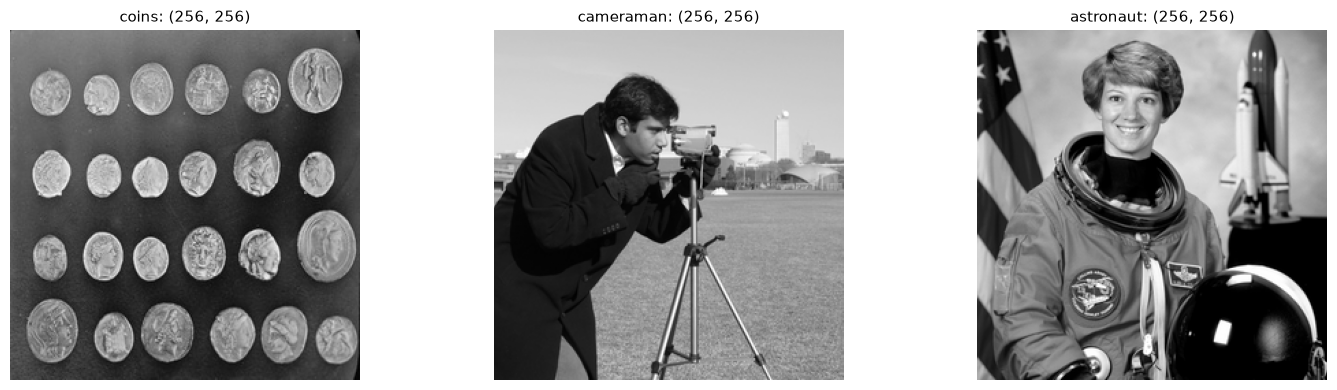

In [2]:
try:
    from skimage import data as skdata
    SKIMAGE_AVAILABLE = True
except ImportError:
    SKIMAGE_AVAILABLE = False
    skdata = None

def as_gray(image):
    """Convierte una imagen 2-D o RGB a float64 en el rango [0, 1]."""
    image = np.asarray(image)
    if image.ndim == 3:
        image = (0.2126 * image[..., 0] +
                  0.7152 * image[..., 1] +
                  0.0722 * image[..., 2])
    image = image.astype(np.float64)
    if image.max() > 1:
        image = image / 255.0
    return np.clip(image, 0.0, 1.0)

def resize_square(image, size=256):
    """Redimensiona una imagen 2-D usando Pillow y conserva [0, 1]."""
    image_u8 = np.uint8(np.round(np.clip(image, 0, 1) * 255))
    resized = Image.fromarray(image_u8).resize((size, size), Image.Resampling.LANCZOS)
    return np.asarray(resized, dtype=np.float64) / 255.0

def local_fallback_images():
    """Usa imágenes del dataset del repositorio si skimage no está instalado."""
    candidates = [Path("tareas/dataset"), Path("../dataset")]
    dataset_dir = next((p for p in candidates if p.exists()), None)
    if dataset_dir is None:
        raise ImportError("Instala scikit-image o ejecuta el notebook desde el repositorio.")
    result = {}
    for name, number in [("coins", 1), ("cameraman", 2), ("astronaut", 3)]:
        path = dataset_dir / f"{number:02d}.png"
        result[name] = np.asarray(Image.open(path).convert("RGB"))
    return result

if SKIMAGE_AVAILABLE:
    raw_images = {
        "coins": skdata.coins(),
        "cameraman": skdata.camera(),
        "astronaut": skdata.astronaut(),
    }
    print("Fuente: skimage.data")
else:
    raw_images = local_fallback_images()
    print("Fuente alternativa: tareas/dataset/*.png")

images = {name: resize_square(as_gray(image), size=256)
          for name, image in raw_images.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, image) in zip(axes, images.items()):
    ax.imshow(image, vmin=0, vmax=1)
    ax.set_title(f"{name}: {image.shape}")
    ax.axis("off")
plt.tight_layout()
fig.savefig(FIG_DIR / "imagenes_entrada.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Ejercicio 1b — Transformaciones Wavelet-2D y DCT-2D

### Wavelet de Haar

En una dimensión, Haar separa cada par de muestras en un promedio y una diferencia:

$$l = \frac{a+b}{\sqrt{2}}, \qquad h = \frac{a-b}{\sqrt{2}}.$$

El factor $1/\sqrt{2}$ hace que la transformación sea ortonormal. La inversa es

$$a = \frac{l+h}{\sqrt{2}}, \qquad b = \frac{l-h}{\sqrt{2}}.$$

En 2-D se aplica la operación primero por filas y luego por columnas. En cada nivel aparecen cuatro subbandas: $LL$ (aproximación), $LH$, $HL$ y $HH$ (detalles). El bloque $LL$ se vuelve a transformar en el siguiente nivel, de modo que los detalles quedan organizados por escala y orientación.

### DCT-2D

La DCT representa la imagen como una suma de cosenos de distintas frecuencias espaciales. Para una imagen $x$ de tamaño $H \times W$, su forma 2-D puede escribirse como

$$\theta_{u,v} = \alpha_u\alpha_v \sum_{i=0}^{H-1}\sum_{j=0}^{W-1} x_{i,j}\cos\!\left(\frac{\pi(2i+1)u}{2H}\right)\cos\!\left(\frac{\pi(2j+1)v}{2W}\right).$$

La normalización es $\alpha_0=1/\sqrt{H}$, $\alpha_u=\sqrt{2/H}$ para $u>0$, y análogamente para $\alpha_v$. El coeficiente $(u,v)=(0,0)$ es la componente DC o promedio. Los coeficientes con $u$ y $v$ grandes representan variaciones rápidas. Se usa normalización ortonormal (`norm="ortho"`), por lo que la energía se conserva.

In [3]:
def haar2d(image, levels=4):
    """Transformada Haar-2D ortonormal con descomposición multinivel."""
    coeff = np.asarray(image, dtype=np.float64).copy()
    h, w = coeff.shape
    if h != w or h % (2 ** levels) != 0:
        raise ValueError("La imagen debe ser cuadrada y divisible por 2**levels.")

    current_h, current_w = h, w
    root2 = np.sqrt(2.0)
    for _ in range(levels):
        block = coeff[:current_h, :current_w]
        # Transformación por filas: bajas a la izquierda, altas a la derecha.
        low_rows = (block[:, 0::2] + block[:, 1::2]) / root2
        high_rows = (block[:, 0::2] - block[:, 1::2]) / root2
        row_transformed = np.concatenate([low_rows, high_rows], axis=1)
        # Transformación por columnas: LL y LH arriba, HL y HH abajo.
        low_cols = (row_transformed[0::2] + row_transformed[1::2]) / root2
        high_cols = (row_transformed[0::2] - row_transformed[1::2]) / root2
        coeff[:current_h, :current_w] = np.concatenate([low_cols, high_cols], axis=0)
        current_h //= 2
        current_w //= 2
    return coeff

def inverse_haar2d(coeff, levels=4):
    """Transformada inversa de Haar-2D."""
    image = np.asarray(coeff, dtype=np.float64).copy()
    h, w = image.shape
    root2 = np.sqrt(2.0)
    for level in range(levels - 1, -1, -1):
        current_h = h // (2 ** level)
        current_w = w // (2 ** level)
        block = image[:current_h, :current_w]
        half_h, half_w = current_h // 2, current_w // 2
        # Invertir columnas.
        row_transformed = np.empty_like(block)
        row_transformed[0::2] = (block[:half_h] + block[half_h:]) / root2
        row_transformed[1::2] = (block[:half_h] - block[half_h:]) / root2
        # Invertir filas.
        low = row_transformed[:, :half_w]
        high = row_transformed[:, half_w:]
        image[:current_h, :current_w][:, 0::2] = (low + high) / root2
        image[:current_h, :current_w][:, 1::2] = (low - high) / root2
    return image

def dct2d(image):
    return dctn(image, type=2, norm="ortho")

def inverse_dct2d(coeff):
    return idctn(coeff, type=2, norm="ortho")

# Comprobación importante: una transformación y su inversa deben recuperar x.
for name, image in images.items():
    haar_error = np.max(np.abs(image - inverse_haar2d(haar2d(image))))
    dct_error = np.max(np.abs(image - inverse_dct2d(dct2d(image))))
    print(f"{name:10s} | error inversa Haar = {haar_error:.2e} | error inversa DCT = {dct_error:.2e}")

coins      | error inversa Haar = 1.44e-15 | error inversa DCT = 7.77e-16
cameraman  | error inversa Haar = 1.67e-15 | error inversa DCT = 9.99e-16
astronaut  | error inversa Haar = 1.78e-15 | error inversa DCT = 8.88e-16


El error de inversión debe estar cerca del error numérico de máquina. Esto verifica que la comparación posterior no está afectada por una implementación incorrecta de las transformaciones. Para una base ortonormal se cumple el teorema de Parseval:

$$\|x\|_2^2 = \|\Psi\theta\|_2^2 = \|\theta\|_2^2.$$

Por eso es válido medir la concentración de energía directamente en el dominio de los coeficientes.

## 5. Ejercicio 1c — Coeficientes ordenados y análisis de dispersión

Para cada transformación se vectoriza $\theta$, se calcula $|\theta|$ y se ordena de mayor a menor. Una caída rápida de la curva indica que unos pocos coeficientes dominan la representación. Además, si $|\theta|_{(1)} \geq \cdots \geq |\theta|_{(n)}$ son las magnitudes ordenadas, la energía acumulada por los primeros $k$ coeficientes se define como

$$E(k) = \frac{\sum_{r=1}^{k}|\theta|_{(r)}^2}{\sum_{r=1}^{n}|\theta|_{(r)}^2}.$$

Para un objetivo $q$ (por ejemplo, $q=0.95$), se reporta

$$k_q = \min\{k : E(k) \geq q\}, \qquad 100\,k_q/n\ \%.$$

Una representación es más compacta según ese criterio cuando necesita un menor porcentaje de coeficientes para alcanzar el mismo $q$.

Esta medida es más informativa que contar valores exactamente iguales a cero: en imágenes naturales casi todos los coeficientes pueden ser distintos de cero debido a ruido, bordes y redimensionamiento, pero muchos pueden ser muy pequeños y eliminarse con poco efecto visual.

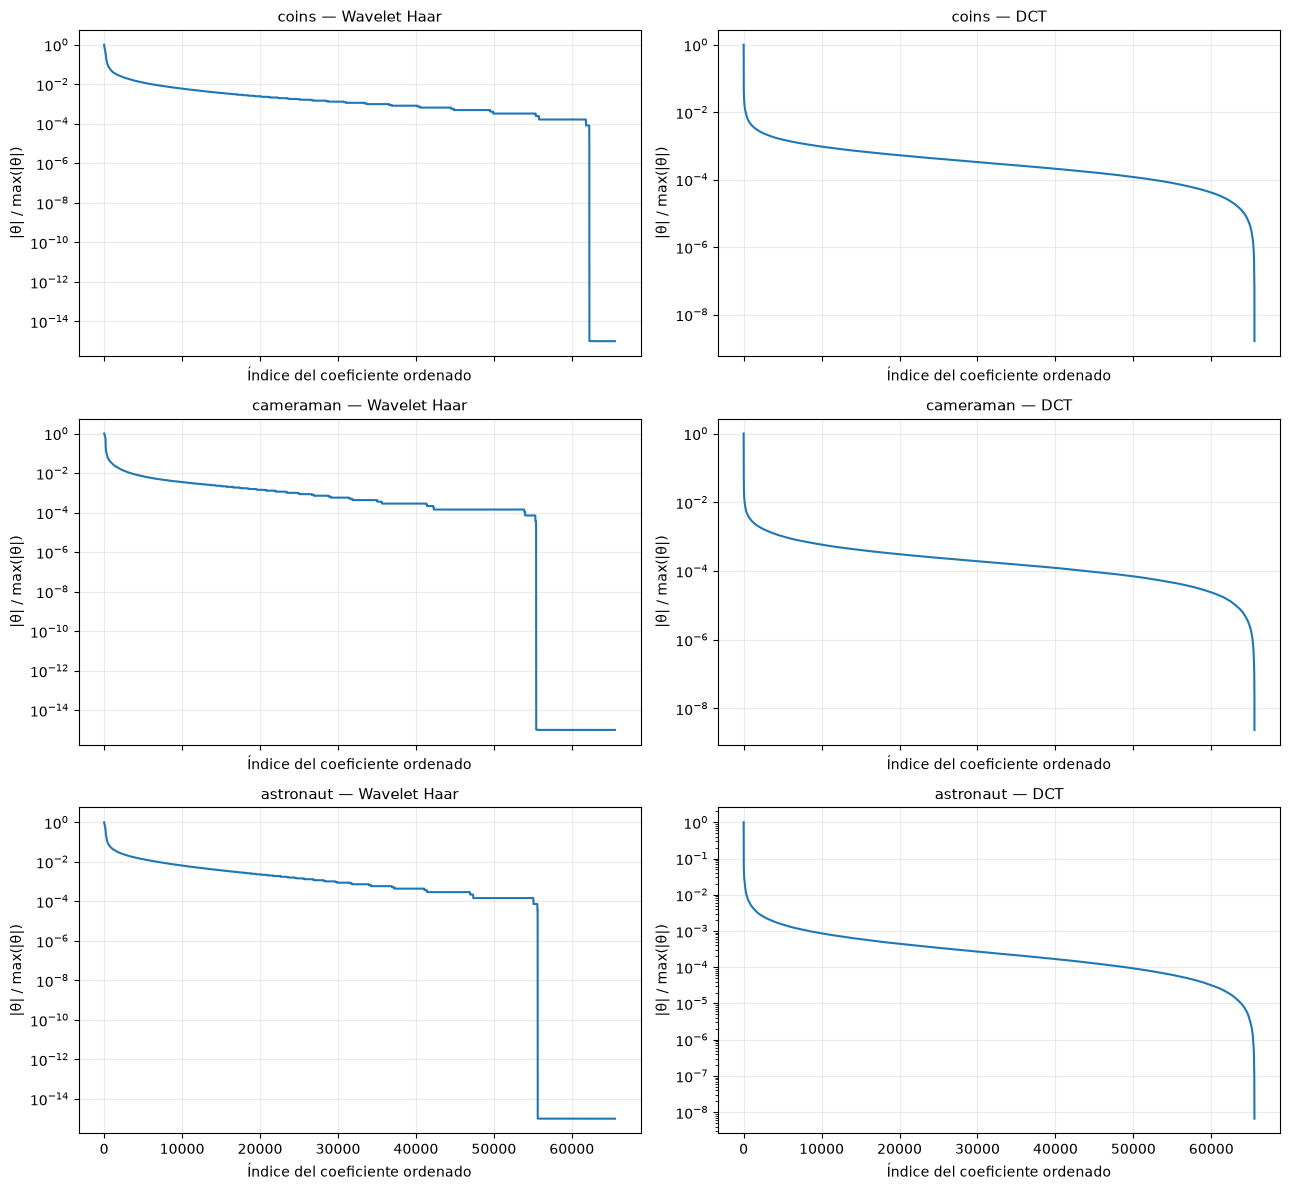

In [4]:
def coefficient_vector(coeff):
    return np.asarray(coeff, dtype=np.float64).ravel()

def sorted_magnitudes(coeff):
    values = np.sort(np.abs(coefficient_vector(coeff)))[::-1]
    return values / max(values[0], np.finfo(float).eps)

def energy_profile(coeff):
    energy = np.sort(coefficient_vector(coeff) ** 2)[::-1]
    total = energy.sum()
    return np.cumsum(energy) / max(total, np.finfo(float).eps)

def percentage_for_energy(coeff, target):
    profile = energy_profile(coeff)
    k = np.searchsorted(profile, target) + 1
    return 100 * k / profile.size

def transform_coefficients(image):
    return {"Wavelet Haar": haar2d(image), "DCT": dct2d(image)}

all_coefficients = {
    image_name: transform_coefficients(image)
    for image_name, image in images.items()
}

fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True)
for row, (image_name, bases) in enumerate(all_coefficients.items()):
    for col, (basis_name, coeff) in enumerate(bases.items()):
        ordered = sorted_magnitudes(coeff)
        axes[row, col].semilogy(np.arange(1, ordered.size + 1), ordered + 1e-15)
        axes[row, col].set_title(f"{image_name} — {basis_name}")
        axes[row, col].set_xlabel("Índice del coeficiente ordenado")
        axes[row, col].set_ylabel("|θ| / max(|θ|)")
        axes[row, col].grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIG_DIR / "coeficientes_ordenados.png", dpi=180, bbox_inches="tight")
plt.show()

In [5]:
dispersion_rows = []
for image_name, bases in all_coefficients.items():
    for basis_name, coeff in bases.items():
        dispersion_rows.append({
            "imagen": image_name,
            "base": basis_name,
            "coeficientes totales": coeff.size,
            "energia con 5% [%]": 100 * energy_profile(coeff)[int(0.05 * coeff.size) - 1],
            "energia con 10% [%]": 100 * energy_profile(coeff)[int(0.10 * coeff.size) - 1],
            "coeficientes para 90% [%]": percentage_for_energy(coeff, 0.90),
            "coeficientes para 95% [%]": percentage_for_energy(coeff, 0.95),
            "coeficientes para 99% [%]": percentage_for_energy(coeff, 0.99),
        })
dispersion = pd.DataFrame(dispersion_rows)
display(dispersion.round(3))

print("Interpretación: una base es más dispersa si necesita un menor porcentaje de coeficientes")
print("para alcanzar el mismo porcentaje de energía, especialmente el 95% o 99%.")

,imagen,base,coeficientes totales,energia con 5% [%],energia con 10% [%],coeficientes para 90% [%],coeficientes para 95% [%],coeficientes para 99% [%]
0,coins,Wavelet Haar,65536,98.893,99.535,0.403,0.854,5.473
1,coins,DCT,65536,98.401,99.050,0.055,0.438,9.430
2,cameraman,Wavelet Haar,65536,99.737,99.888,0.250,0.290,1.329
3,cameraman,DCT,65536,99.381,99.663,0.009,0.041,2.460
4,astronaut,Wavelet Haar,65536,98.924,99.576,0.352,0.761,5.339
5,astronaut,DCT,65536,98.780,99.346,0.127,0.520,6.357


Interpretación: una base es más dispersa si necesita un menor porcentaje de coeficientes
para alcanzar el mismo porcentaje de energía, especialmente el 95% o 99%.


In [6]:
for target in [0.95, 0.99]:
    column = f"coeficientes para {int(100 * target)}% [%]"
    print(f"Criterio: menor porcentaje para acumular {int(100 * target)}% de energía")
    for image_name, group in dispersion.groupby("imagen"):
        winner = group.loc[group[column].idxmin()]
        print(
            f"  {image_name:10s}: {winner['base']} — "
            f"{winner[column]:.3f}% de los coeficientes."
        )
    print()

Criterio: menor porcentaje para acumular 95% de energía
  astronaut : DCT — 0.520% de los coeficientes.
  cameraman : DCT — 0.041% de los coeficientes.
  coins     : DCT — 0.438% de los coeficientes.

Criterio: menor porcentaje para acumular 99% de energía
  astronaut : Wavelet Haar — 5.339% de los coeficientes.
  cameraman : Wavelet Haar — 1.329% de los coeficientes.
  coins     : Wavelet Haar — 5.473% de los coeficientes.



### Análisis del ejercicio 1

En imágenes naturales, la información suele concentrarse en bajas frecuencias y en bordes. La DCT concentra especialmente la energía de regiones suaves en coeficientes cercanos a la esquina DC, mientras que Haar localiza los cambios abruptos en coeficientes de detalle y además los organiza por escala.

La tabla anterior permite evitar una conclusión basada solamente en la apariencia de la gráfica: para cada imagen se debe comparar `coeficientes para 95%` o `coeficientes para 99%`. La base con el porcentaje menor es la representación más dispersa para ese nivel de energía. El nivel elegido debe mencionarse explícitamente: una base puede ganar al 95% y perder al 99% porque las curvas de energía pueden cruzarse. La dispersión depende de la textura, los bordes y la suavidad de cada contenido.

## 6. Ejercicio 2a–2b — Eliminación de coeficientes

Se define una función que recibe el vector de coeficientes $\theta$ y un porcentaje $P$. Si $n$ es el número total de coeficientes, se conserva

$$K = \left\lceil\frac{P}{100}\,n\right\rceil$$

coeficientes, escogiendo los $K$ de mayor magnitud. El vector truncado queda definido por

$$\theta^{(P)}_r = \begin{cases}
\theta_r, & r \in \mathcal{I}_K,\\
0, & r \notin \mathcal{I}_K,
\end{cases}$$

donde $\mathcal{I}_K$ contiene los índices de los $K$ valores más grandes de $|\theta_r|$. Esto implementa un umbral duro (*hard thresholding*). Es importante ordenar por $|\theta|$, no por $\theta$, porque un coeficiente negativo grande también contiene mucha energía.

In [7]:
def eliminate_coefficients(theta, P):
    """Conserva el porcentaje P de coeficientes de mayor magnitud.

    Parámetros
    ----------
    theta : array-like
        Vector de coeficientes de la representación.
    P : float
        Porcentaje de coeficientes no nulos que se conserva, entre 0 y 100.
    """
    theta = np.asarray(theta, dtype=np.float64).ravel()
    if not 0 < P <= 100:
        raise ValueError("P debe estar en el intervalo (0, 100].")

    number_to_keep = max(1, int(np.ceil(P * theta.size / 100)))
    largest = np.argsort(np.abs(theta))[::-1][:number_to_keep]
    sparse_theta = np.zeros_like(theta)
    sparse_theta[largest] = theta[largest]
    return sparse_theta

# Prueba mínima de la función pedida en el enunciado.
example_theta = np.array([0.1, -4.0, 0.5, 2.0, -0.2])
print("θ original:   ", example_theta)
print("θ con P=40%:  ", eliminate_coefficients(example_theta, 40))

θ original:    [ 0.1 -4.   0.5  2.  -0.2]
θ con P=40%:   [ 0. -4.  0.  2.  0.]


## 7. Ejercicio 2c — Reconstrucción para distintos porcentajes

El experimento se repite para `coins`, `cameraman` y `astronaut`. Para cada imagen y cada base se transforma la imagen, se vectoriza el resultado, se aplica `eliminate_coefficients`, se vuelve a dar forma matricial y finalmente se aplica la transformación inversa.

La saturación a `[0, 1]` se realiza solamente para mostrar y evaluar una imagen válida. La transformación inversa puede producir valores ligeramente fuera del rango por el truncamiento de coeficientes.

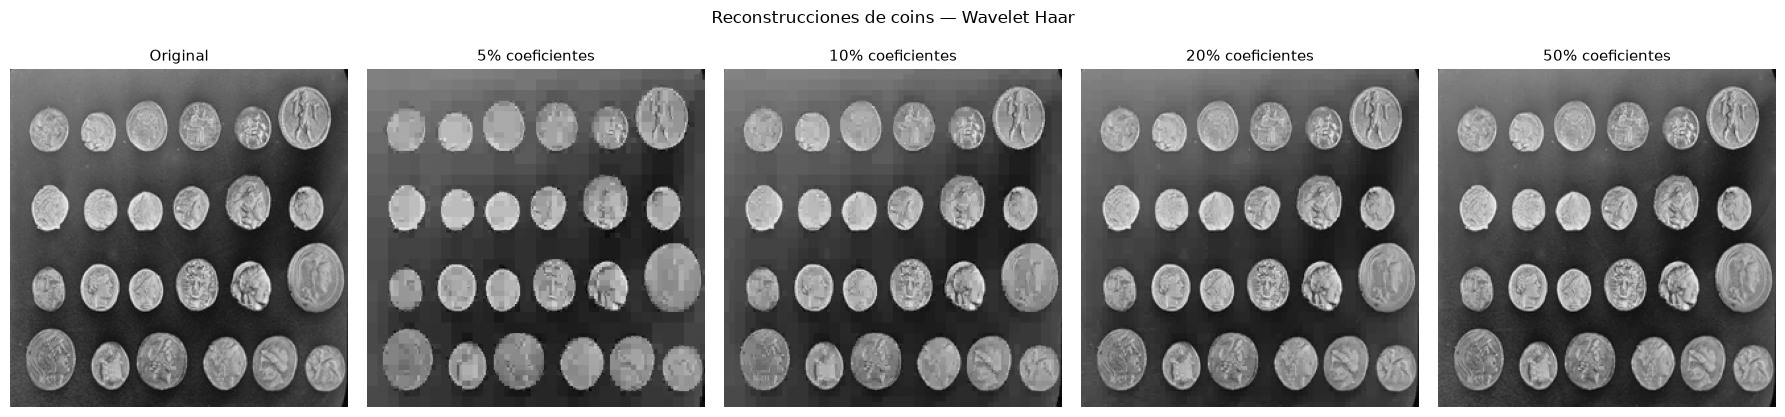

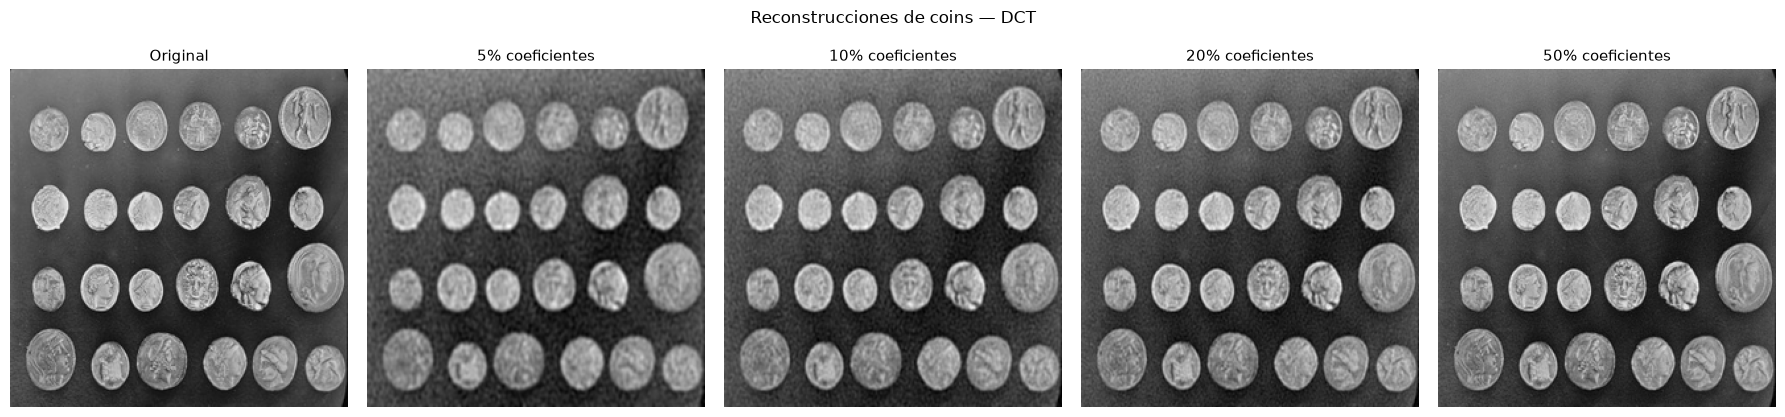

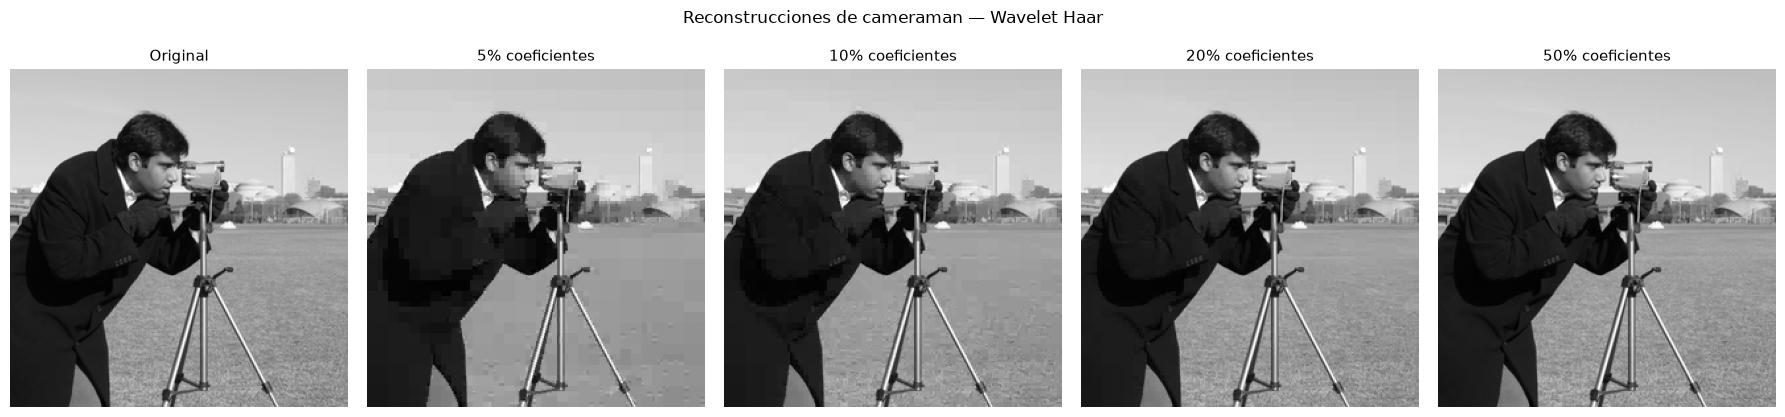

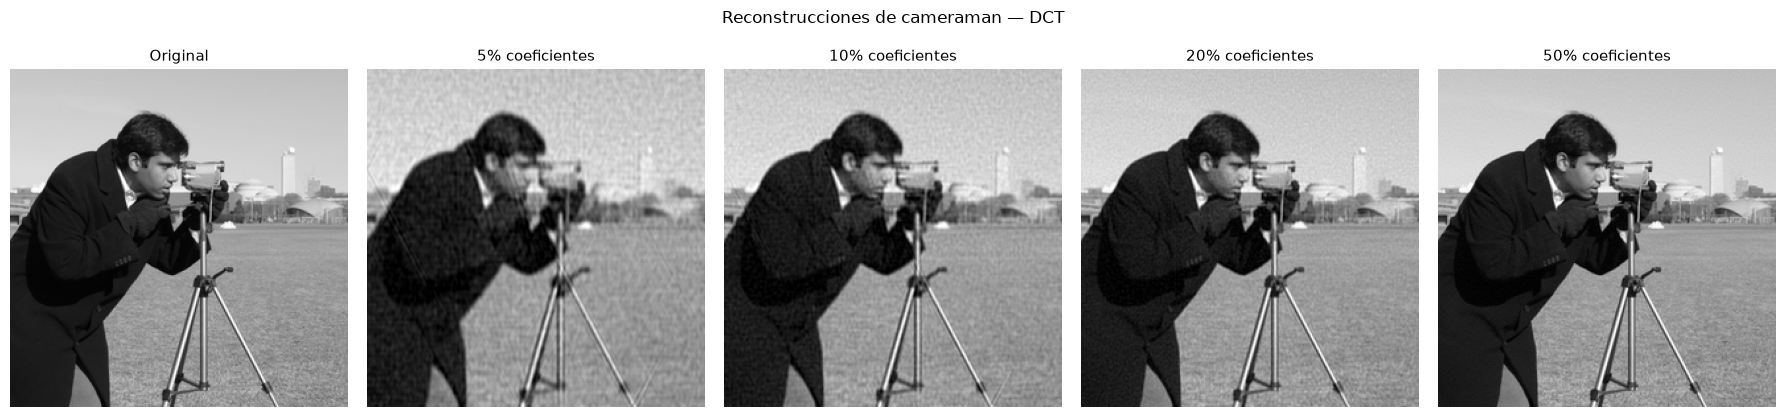

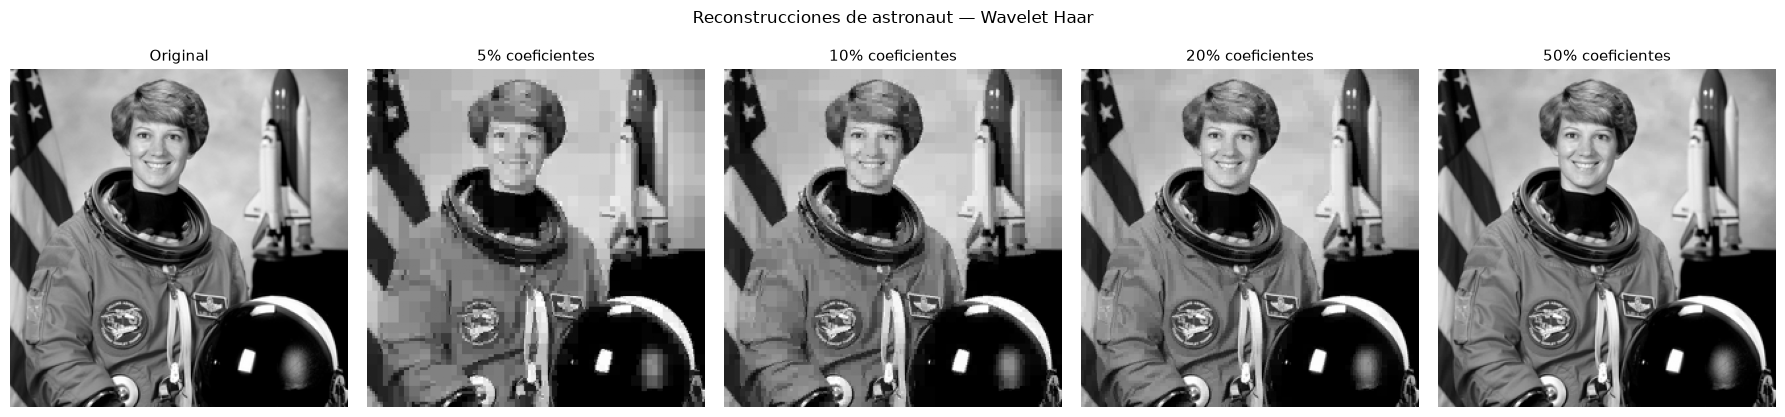

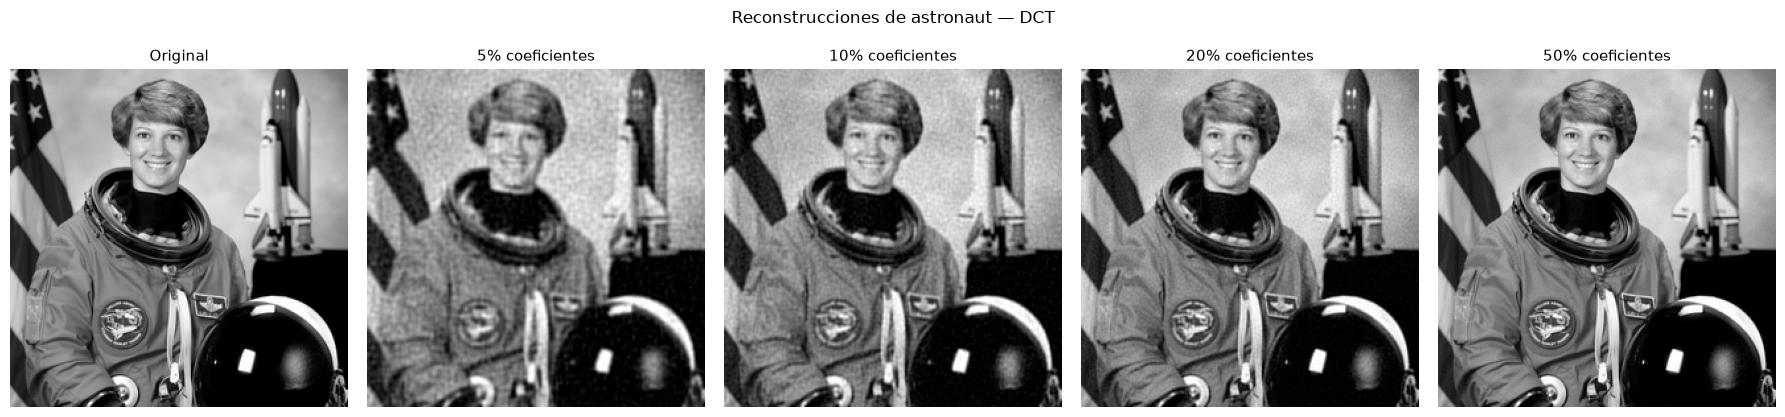

In [8]:
image_names = list(images)
percentages = [5, 10, 20, 50]

def sparse_reconstruction(image, basis_name, P):
    if basis_name == "Wavelet Haar":
        coeff = haar2d(image)
        sparse = eliminate_coefficients(coeff.ravel(), P).reshape(coeff.shape)
        reconstruction = inverse_haar2d(sparse)
    elif basis_name == "DCT":
        coeff = dct2d(image)
        sparse = eliminate_coefficients(coeff.ravel(), P).reshape(coeff.shape)
        reconstruction = inverse_dct2d(sparse)
    else:
        raise ValueError("Base no reconocida.")
    return np.clip(reconstruction, 0.0, 1.0)

reconstructions = {
    image_name: {
        basis_name: {P: sparse_reconstruction(images[image_name], basis_name, P)
                      for P in percentages}
        for basis_name in ["Wavelet Haar", "DCT"]
    }
    for image_name in image_names
}

for image_name in image_names:
    for basis_name, recon_by_percentage in reconstructions[image_name].items():
        fig, axes = plt.subplots(1, 5, figsize=(18, 4))
        axes[0].imshow(images[image_name], vmin=0, vmax=1)
        axes[0].set_title("Original")
        axes[0].axis("off")
        for ax, P in zip(axes[1:], percentages):
            ax.imshow(recon_by_percentage[P], vmin=0, vmax=1)
            ax.set_title(f"{P}% coeficientes")
            ax.axis("off")
        fig.suptitle(f"Reconstrucciones de {image_name} — {basis_name}", y=1.03)
        plt.tight_layout()
        filename = "haar" if basis_name == "Wavelet Haar" else "dct"
        fig.savefig(FIG_DIR / f"reconstruccion_{image_name}_{filename}.png", dpi=180, bbox_inches="tight")
        plt.show()

## 8. Ejercicio 2d — MSE y PSNR

El error cuadrático medio (MSE) promedia el cuadrado del error en todos los píxeles:

$$\operatorname{MSE}(x,\hat{x}) = \frac{1}{n}\sum_{i=1}^{n}(x_i-\hat{x}_i)^2 = \frac{1}{HW}\sum_{i=1}^{H}\sum_{j=1}^{W}(x_{i,j}-\hat{x}_{i,j})^2.$$

Como las imágenes están normalizadas a $[0,1]$, $MAX_I=1$. El PSNR compara el máximo rango dinámico con el MSE:

$$\operatorname{PSNR}(x,\hat{x}) = 10\log_{10}\!\left(\frac{MAX_I^2}{\operatorname{MSE}(x,\hat{x})}\right) = 10\log_{10}\!\left(\frac{1}{\operatorname{MSE}(x,\hat{x})}\right)\ \text{dB}.$$

Como las bases son ortonormales, si no se aplicara la saturación a $[0,1]$, el error total de truncar sería exactamente la energía descartada:

$$\|x-\hat{x}\|_2^2 = \sum_{r\notin\mathcal{I}_K}|\theta_r|^2.$$

Al dividir por $n$ se obtiene el MSE. En el código se satura la reconstrucción a $[0,1]$ antes de evaluar, por lo que esta igualdad puede cambiar ligeramente en los píxeles que salen del rango. Por lo tanto, un MSE menor produce un PSNR mayor. Si el MSE fuera cero, el PSNR sería infinito; en este experimento los valores que aparecen como `0.00000` son solo redondeo. Conviene leer PSNR junto con las figuras, porque dos reconstrucciones pueden tener valores parecidos y artefactos visuales distintos.

,imagen,base,P [%],coeficientes no nulos,MSE,PSNR [dB]
0,coins,Wavelet Haar,5,3277,2.060e-03,26.86
1,coins,Wavelet Haar,10,6554,8.679e-04,30.62
2,coins,Wavelet Haar,20,13108,2.627e-04,35.80
3,coins,Wavelet Haar,50,32768,2.268e-05,46.44
4,coins,DCT,5,3277,2.981e-03,25.26
5,coins,DCT,10,6554,1.771e-03,27.52
6,coins,DCT,20,13108,8.251e-04,30.83
7,coins,DCT,50,32768,1.157e-04,39.37
8,cameraman,Wavelet Haar,5,3277,8.872e-04,30.52
9,cameraman,Wavelet Haar,10,6554,3.786e-04,34.22


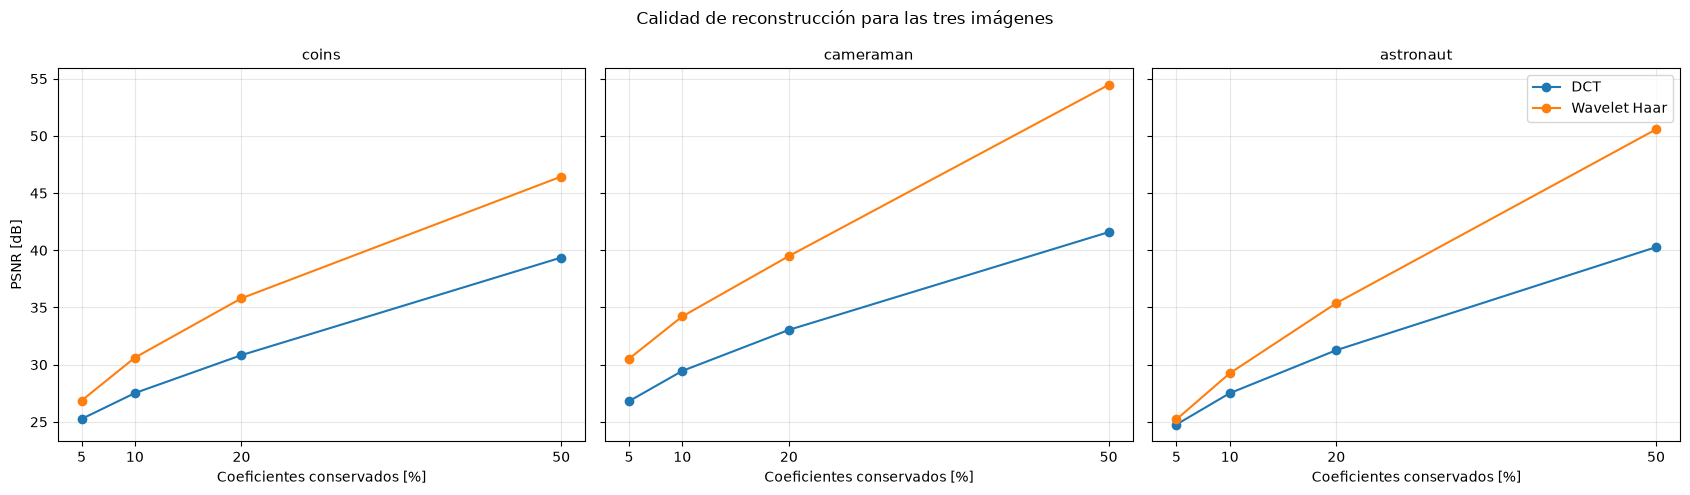

In [9]:
def mse(reference, estimate):
    return float(np.mean((reference - estimate) ** 2))

def psnr(reference, estimate, data_range=1.0):
    error = mse(reference, estimate)
    if error == 0:
        return np.inf
    return float(10 * np.log10((data_range ** 2) / error))

reconstruction_rows = []
for image_name in image_names:
    image = images[image_name]
    for basis_name, recon_by_percentage in reconstructions[image_name].items():
        for P, reconstruction in recon_by_percentage.items():
            reconstruction_rows.append({
                "imagen": image_name,
                "base": basis_name,
                "P [%]": P,
                "coeficientes no nulos": int(np.ceil(P * image.size / 100)),
                "MSE": mse(image, reconstruction),
                "PSNR [dB]": psnr(image, reconstruction),
            })

reconstruction_results = pd.DataFrame(reconstruction_rows)
# Formato de presentación: el MSE se muestra en notación científica para
# no confundir un valor pequeño con un error exactamente igual a cero.
results_for_display = reconstruction_results.copy()
results_for_display["MSE"] = results_for_display["MSE"].map(lambda value: f"{value:.3e}")
results_for_display["PSNR [dB]"] = results_for_display["PSNR [dB]"].map(lambda value: f"{value:.2f}")
display(results_for_display)

fig, axes = plt.subplots(1, len(image_names), figsize=(17, 5), sharey=True)
for ax, image_name in zip(np.atleast_1d(axes), image_names):
    group = reconstruction_results[reconstruction_results["imagen"] == image_name]
    for basis_name, basis_group in group.groupby("base"):
        ax.plot(basis_group["P [%]"], basis_group["PSNR [dB]"], marker="o", label=basis_name)
    ax.set_title(image_name)
    ax.set_xlabel("Coeficientes conservados [%]")
    ax.set_xticks(percentages)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("PSNR [dB]")
axes[-1].legend()
fig.suptitle("Calidad de reconstrucción para las tres imágenes")
plt.tight_layout()
fig.savefig(FIG_DIR / "psnr_tres_imagenes.png", dpi=180, bbox_inches="tight")
plt.show()

### Lectura esperada de las reconstrucciones

- Con 5% aparecen las estructuras globales, pero se pierden texturas y detalles finos.
- Con 10% y 20% se recuperan las formas principales y buena parte de los bordes.
- Con 50% la imagen normalmente es visualmente cercana a la original y el PSNR aumenta de forma importante.

En Haar, los detalles están localizados espacialmente y suelen aparecer como bloques o bordes cuando se conserva un porcentaje pequeño. En DCT, la energía de regiones suaves tiende a concentrarse en bajas frecuencias; al eliminar coeficientes de alta frecuencia la imagen se ve más suavizada. Estas observaciones deben contrastarse con la tabla y no reemplazan los valores medidos. Las diferencias entre `coins`, `cameraman` y `astronaut` reflejan que la escasez depende del contenido de cada imagen.

## 9. Ejercicio 2e — Conclusiones

Hay dos preguntas relacionadas, pero no idénticas:

1. **Dispersión:** ¿cuántos coeficientes necesito para conservar una fracción determinada de la energía? Se responde comparando $k_{95}$ o $k_{99}$.
2. **Calidad a un presupuesto fijo:** si conservo exactamente $P\%$ de los coeficientes, ¿qué reconstrucción tiene mayor PSNR? Se responde con la tabla de MSE y PSNR.

No existe contradicción si una base es mejor en la primera pregunta y otra en la segunda. Por ejemplo, una base puede alcanzar el 95% de energía con muy pocos coeficientes, pero distribuir mejor la energía restante y obtener menor MSE cuando se fija $P=5\%$ o $P=50\%$. La siguiente celda imprime ambos criterios.

In [10]:
for image_name in image_names:
    selected_dispersion = dispersion[dispersion["imagen"] == image_name].copy()
    best_sparse_95 = selected_dispersion.loc[selected_dispersion["coeficientes para 95% [%]"].idxmin()]
    best_sparse_99 = selected_dispersion.loc[selected_dispersion["coeficientes para 99% [%]"].idxmin()]
    print(f"Para {image_name}, usando el 95% de energía, la base más dispersa es")
    print(f"  {best_sparse_95['base']} ({best_sparse_95['coeficientes para 95% [%]']:.3f}% de los coeficientes).")
    print(f"Usando el 99% de energía, la base más dispersa es")
    print(f"  {best_sparse_99['base']} ({best_sparse_99['coeficientes para 99% [%]']:.3f}% de los coeficientes).")

    image_results = reconstruction_results[reconstruction_results["imagen"] == image_name]
    best_psnr = image_results.loc[image_results.groupby("P [%]")["PSNR [dB]"].idxmax()]
    print("Mejor PSNR por porcentaje conservado:")
    display(best_psnr[["P [%]", "base", "PSNR [dB]"]].sort_values("P [%]").round(3))
    print()


print("Interpretación: la base que necesita menos coeficientes es más dispersa para ese nivel de energía.")
print("El mejor PSNR a un P fijo puede pertenecer a otra base, porque compara un porcentaje de coeficientes, no un porcentaje de energía.")

Para coins, usando el 95% de energía, la base más dispersa es
  DCT (0.438% de los coeficientes).
Usando el 99% de energía, la base más dispersa es
  Wavelet Haar (5.473% de los coeficientes).
Mejor PSNR por porcentaje conservado:


,P [%],base,PSNR [dB]
0,5,Wavelet Haar,26.862
1,10,Wavelet Haar,30.615
2,20,Wavelet Haar,35.805
3,50,Wavelet Haar,46.444



Para cameraman, usando el 95% de energía, la base más dispersa es
  DCT (0.041% de los coeficientes).
Usando el 99% de energía, la base más dispersa es
  Wavelet Haar (1.329% de los coeficientes).
Mejor PSNR por porcentaje conservado:


,P [%],base,PSNR [dB]
8,5,Wavelet Haar,30.520
9,10,Wavelet Haar,34.219
10,20,Wavelet Haar,39.494
11,50,Wavelet Haar,54.459



Para astronaut, usando el 95% de energía, la base más dispersa es
  DCT (0.520% de los coeficientes).
Usando el 99% de energía, la base más dispersa es
  Wavelet Haar (5.339% de los coeficientes).
Mejor PSNR por porcentaje conservado:


,P [%],base,PSNR [dB]
16,5,Wavelet Haar,25.214
17,10,Wavelet Haar,29.246
18,20,Wavelet Haar,35.381
19,50,Wavelet Haar,50.572



Interpretación: la base que necesita menos coeficientes es más dispersa para ese nivel de energía.
El mejor PSNR a un P fijo puede pertenecer a otra base, porque compara un porcentaje de coeficientes, no un porcentaje de energía.


### Conclusión general

La escasez no es una propiedad absoluta de una imagen: depende de la base elegida, del contenido de la imagen y del nivel de energía que se fija como criterio. Wavelet Haar y DCT son transformaciones ortonormales, por lo que permiten reconstruir exactamente al conservar todos los coeficientes, pero concentran la energía de maneras diferentes.

Los resultados concretos para `coins`, `cameraman` y `astronaut` se imprimen en las celdas anteriores y se guardan en `dispersion_por_imagen.csv`. Por eso la conclusión debe indicar, para cada imagen, qué base necesita menos coeficientes al 95% y al 99% de energía; una base puede ser mejor en un umbral y otra en el segundo.

Para cada una de las tres imágenes, la tabla de MSE y PSNR permite determinar qué base entrega la mejor calidad a un porcentaje fijo de coeficientes. No se debe generalizar el resultado de `cameraman`: `coins` y `astronaut` pueden favorecer otra base debido a sus texturas, bordes y regiones suaves. Las figuras de reconstrucción permiten complementar esta comparación numérica con la inspección visual de los artefactos.

El MSE disminuye cuando aumenta $P$ y el PSNR aumenta porque
$$\operatorname{PSNR} = 10\log_{10}\!\left(\frac{1}{\operatorname{MSE}}\right).$$
Los valores muy pequeños de MSE deben leerse en notación científica; un valor mostrado como `0.00000` por redondeo no significa que la reconstrucción sea exacta.

Desde el punto de vista de muestreo comprimido, una representación dispersa es útil porque permite describir aproximadamente $x$ con pocos elementos de $\theta$. La tarea todavía no reconstruye a partir de mediciones comprimidas $y=A\Psi\theta$; estudia la condición previa: encontrar una base donde $\theta$ sea suficientemente escaso para que una recuperación posterior sea posible.

## 10. Exportación de resultados

Las tablas y figuras quedan guardadas automáticamente para que el informe use exactamente los resultados de esta ejecución.

In [11]:
dispersion.round(8).to_csv(RESULTS_DIR / "dispersion_por_imagen.csv", index=False)
reconstruction_results.round(8).to_csv(RESULTS_DIR / "reconstruccion_por_imagen.csv", index=False)
for image_name in image_names:
    reconstruction_results[reconstruction_results["imagen"] == image_name].round(8).to_csv(
        RESULTS_DIR / f"reconstruccion_{image_name}.csv", index=False
    )
print(f"Resultados guardados en: {RESULTS_DIR}")

Resultados guardados en: resultados


## 11. Comparación ampliada (zoom)

Se inspecciona la misma zona relativa de cada imagen para comparar visualmente el efecto de conservar distintos porcentajes de coeficientes.

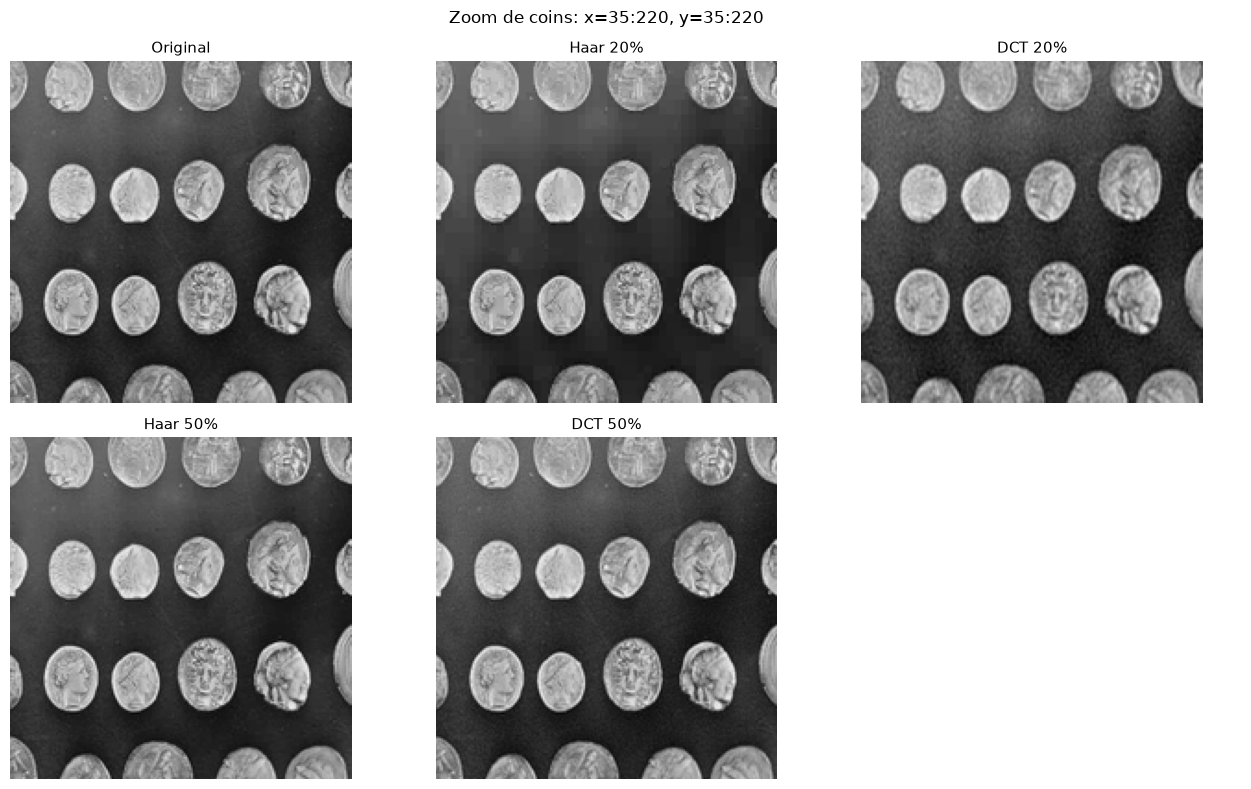

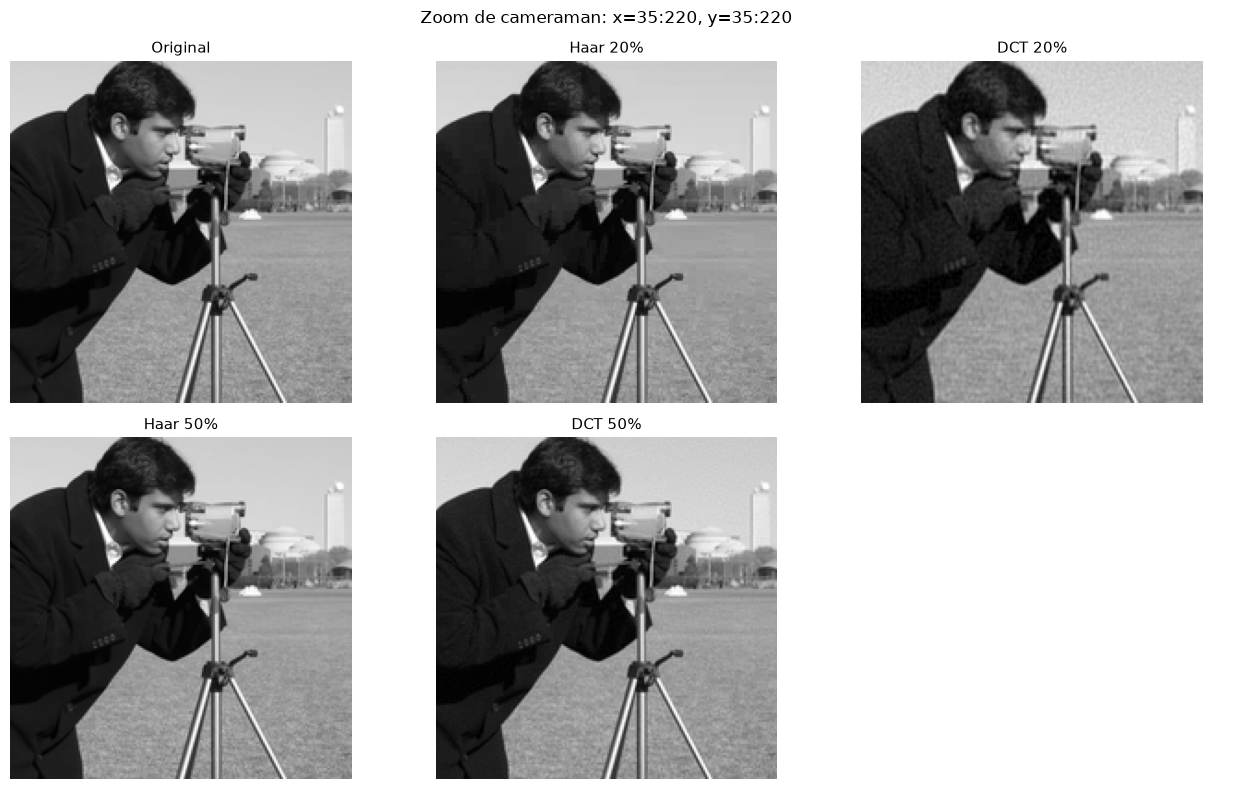

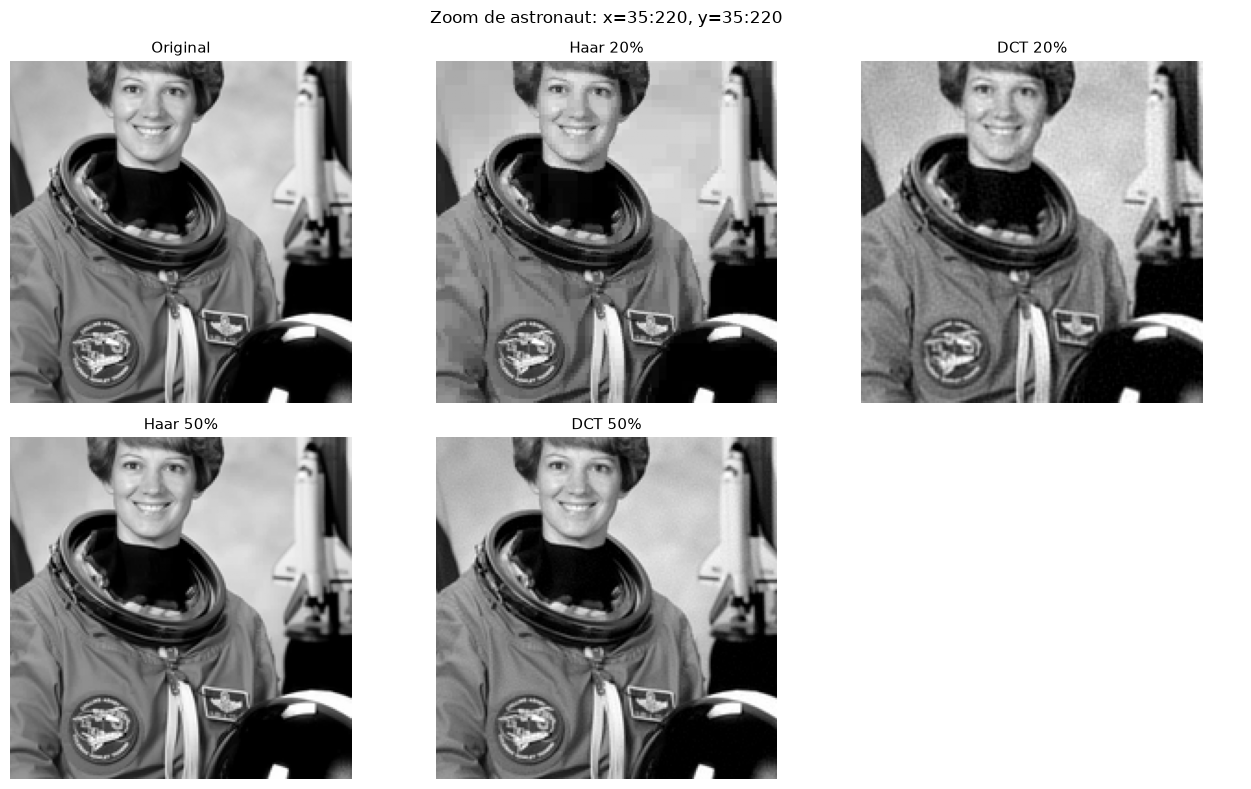

Zoom y tablas exportados correctamente.


In [12]:
x0, y0, x1, y1 = 35, 35, 220, 220
for image_name in image_names:
    zoom_items = [
        ("Original", images[image_name]),
        ("Haar 20%", reconstructions[image_name]["Wavelet Haar"][20]),
        ("DCT 20%", reconstructions[image_name]["DCT"][20]),
        ("Haar 50%", reconstructions[image_name]["Wavelet Haar"][50]),
        ("DCT 50%", reconstructions[image_name]["DCT"][50]),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for ax, (title, image) in zip(axes.flat, zoom_items):
        ax.imshow(image[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    axes.flat[-1].axis("off")
    fig.suptitle(f"Zoom de {image_name}: x={x0}:{x1}, y={y0}:{y1}")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"zoom_{image_name}_comparacion.png", dpi=200, bbox_inches="tight")
    plt.show()

dispersion.round(8).to_csv(RESULTS_DIR / "dispersion_por_imagen.csv", index=False)
reconstruction_results.round(8).to_csv(RESULTS_DIR / "reconstruccion_por_imagen.csv", index=False)
print("Zoom y tablas exportados correctamente.")